# Clasificación de Riesgo Crediticio — Baseline con Random Forest y Gradient Boosting

## Propósito
Construir un pipeline reproducible de clasificación binaria sobre el German Credit Dataset
(1,000 instancias, 10 variables mixtas) para predecir `Risk` = {good, bad}.
Este baseline servirá como referencia cuantitativa para comparar contra TabPFN
(Hollmann et al., 2023), un foundation model basado en transformers para datos tabulares pequeños.

## Dataset
- **German Credit Dataset** (UCI / Kaggle)
- 1,000 muestras, clasificación binaria
- 9 predictores: edad, sexo, empleo, vivienda, cuentas de ahorro/cheques, monto, duración y propósito
- Fuente: https://www.kaggle.com/datasets/uciml/german-credit

## Referencia
Hollmann, N., Müller, S., Purucker, L. et al. (2023).
_Accurate predictions on small data with a tabular foundation model._ Nature.
https://doi.org/10.1038/s41586-024-08328-6


In [21]:
# Imports
import os, sys, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


In [22]:
# Configuración global — modificar aquí para experimentos
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
TARGET = 'Risk'
POS_CLASS = 'good'
NEG_CLASS = 'bad'
DATA_PATH = '/content/drive/MyDrive/ML/german_credit_data.csv'

sns.set_theme(style='whitegrid', palette='Set2')

## Carga de Datos
Montamos Google Drive y cargamos el dataset. Si el archivo no existe,
se indica cómo descargarlo manualmente desde Kaggle.


In [23]:
from google.colab import drive
drive.mount('/content/drive')

# Verificar existencia y cargar
if not os.path.exists(DATA_PATH):
    print(f'Dataset no encontrado en {DATA_PATH}')
    print('Descargar manualmente de Kaggle: uciml/german-credit')
    raise FileNotFoundError(f'Falta el archivo: {DATA_PATH}')

df = pd.read_csv(DATA_PATH, index_col=0)
print(f'Dimensiones: {df.shape}')
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensiones: (1000, 10)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## Análisis Exploratorio de Datos
Inspeccionamos calidad del dataset, balance de clases, distribuciones y relaciones
relevantes antes de modelar.


In [24]:
# Valores nulos y duplicados
nulls = df.isnull().sum()
print('Valores nulos:')
print(nulls[nulls > 0] if nulls.any() else 'Ninguno')
print(f'Duplicados: {df.duplicated().sum()}')

# Balance de la variable objetivo
balance = df[TARGET].value_counts()
balance_pct = df[TARGET].value_counts(normalize=True) * 100
print(f'\nBalance de {TARGET}:')
for k, v in balance.items():
    print(f'  {k:6s}: {v:4d} ({balance_pct[k]:.1f}%)')
print(f'  Ratio good:bad = {balance.get("good", 0)/balance.get("bad", 1):.2f}:1')


Valores nulos:
Saving accounts     183
Checking account    394
dtype: int64
Duplicados: 0

Balance de Risk:
  good  :  700 (70.0%)
  bad   :  300 (30.0%)
  Ratio good:bad = 2.33:1


### Estadísticas descriptivas
Separo numéricas y categóricas para entender rangos, frecuencias y valores típicos.


In [25]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.select_dtypes(include=['object', 'category']).columns.tolist() if c != TARGET]

print('Numéricas:')
print(df[num_cols].describe().T.round(2))

print('\nCategóricas:')
for c in cat_cols:
    print(f'\n{c} — {df[c].nunique()} valores')
    print(df[c].value_counts().to_string())


Numéricas:
                count     mean      std    min     25%     50%      75%  \
Age            1000.0    35.55    11.38   19.0    27.0    33.0    42.00   
Job            1000.0     1.90     0.65    0.0     2.0     2.0     2.00   
Credit amount  1000.0  3271.26  2822.74  250.0  1365.5  2319.5  3972.25   
Duration       1000.0    20.90    12.06    4.0    12.0    18.0    24.00   

                   max  
Age               75.0  
Job                3.0  
Credit amount  18424.0  
Duration          72.0  

Categóricas:

Sex — 2 valores
Sex
male      690
female    310

Housing — 3 valores
Housing
own     713
rent    179
free    108

Saving accounts — 4 valores
Saving accounts
little        603
moderate      103
quite rich     63
rich           48

Checking account — 3 valores
Checking account
little      274
moderate    269
rich         63

Purpose — 8 valores
Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education  

### Visualizaciones
Gráficos exploratorios individuales para entender la relación entre
cada variable y el riesgo crediticio.


#### Distribución de Risk


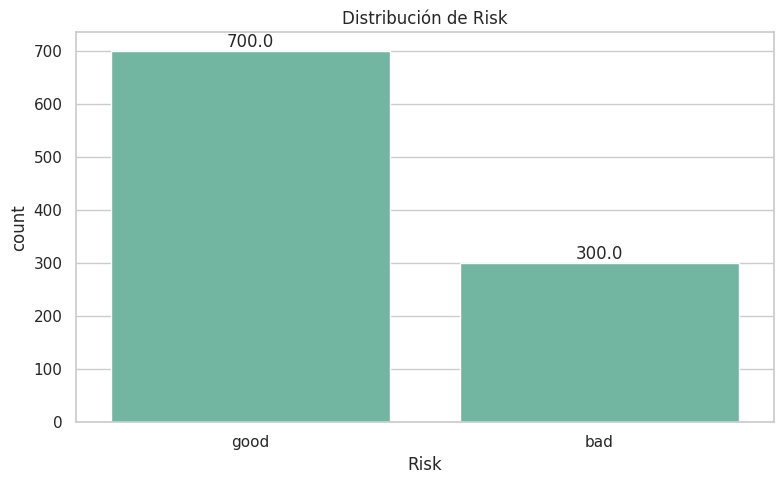

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_title('Distribución de Risk')
for p in ax.patches:
    ax.annotate(str(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom')
plt.tight_layout()
plt.show()

#### Edad por Risk


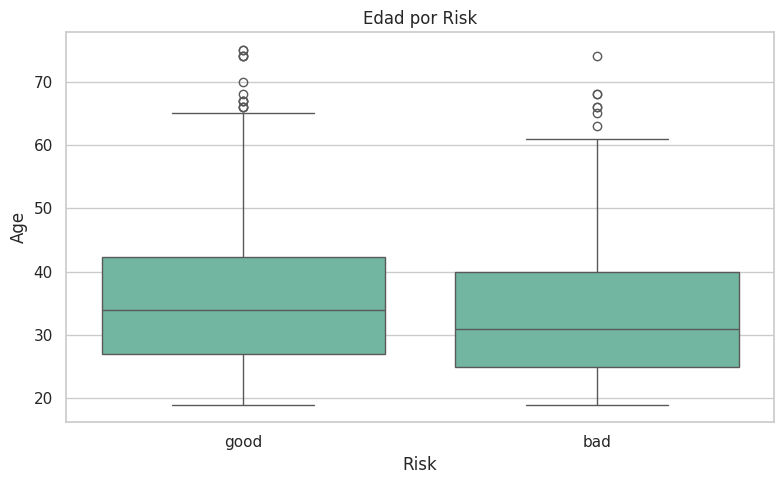

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x=TARGET, y='Age', ax=ax)
ax.set_title('Edad por Risk')
plt.tight_layout()
plt.show()

#### Monto de crédito por Risk


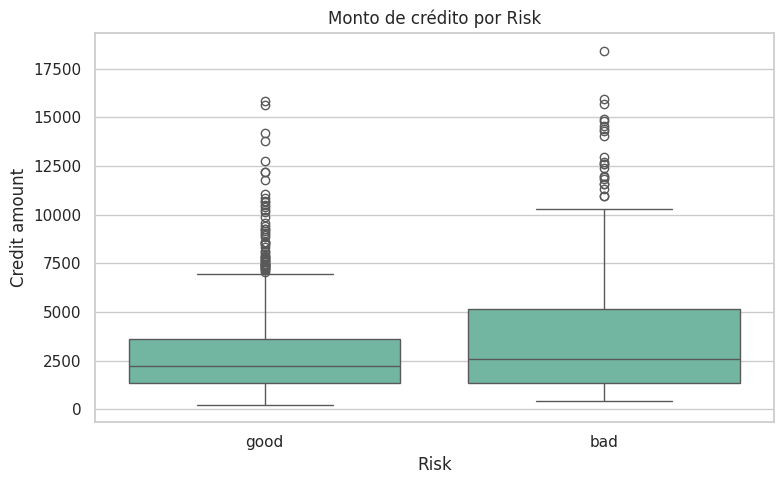

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x=TARGET, y='Credit amount', ax=ax)
ax.set_title('Monto de crédito por Risk')
plt.tight_layout()
plt.show()

#### Duración del crédito por Risk


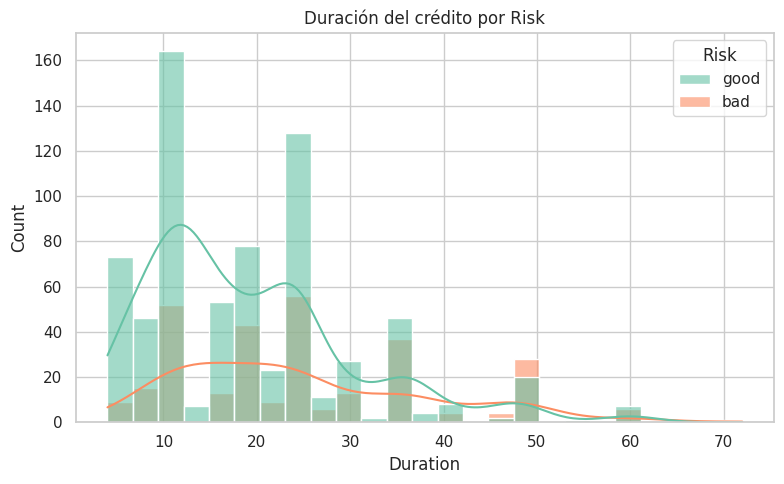

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x='Duration', hue=TARGET, kde=True, bins=25, alpha=0.6, ax=ax)
ax.set_title('Duración del crédito por Risk')
plt.tight_layout()
plt.show()

#### Vivienda vs Risk


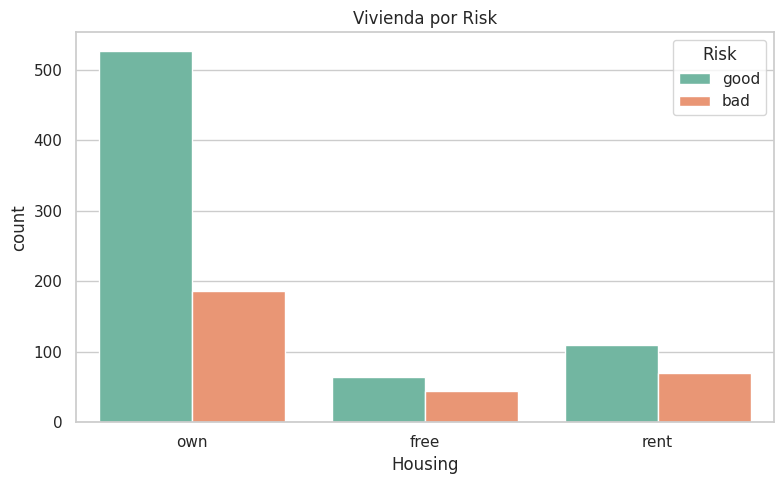

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x='Housing', hue=TARGET, ax=ax)
ax.set_title('Vivienda por Risk')
plt.tight_layout()
plt.show()

#### Sexo vs Risk


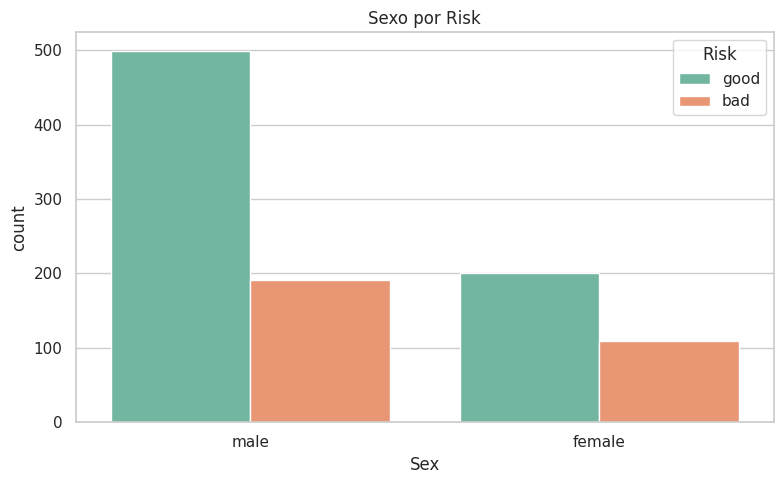

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x='Sex', hue=TARGET, ax=ax)
ax.set_title('Sexo por Risk')
plt.tight_layout()
plt.show()

### Correlaciones entre variables numéricas
Uso Spearman porque las distribuciones no son normales (hay asimetría).


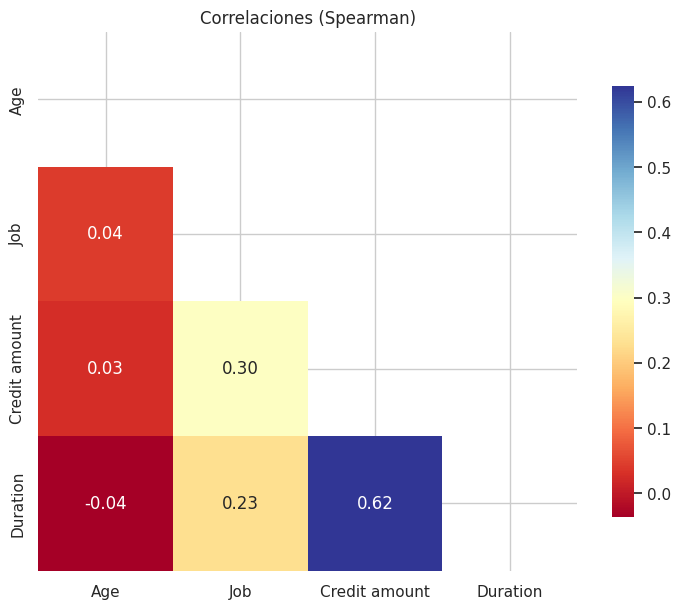

In [32]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df[num_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu',
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlaciones (Spearman)')
plt.show()


### Proporción de malos pagadores por propósito
Identificamos qué tipos de crédito tienen mayor incidencia de impago.


In [33]:
ct = pd.crosstab(df['Purpose'], df[TARGET], normalize='index') * 100
ct = ct.round(2).sort_values(by='bad', ascending=False)
ct.columns = ['Good (%)', 'Bad (%)']
print('Malos pagadores por propósito:')
print(ct)


Malos pagadores por propósito:
                     Good (%)  Bad (%)
Purpose                               
vacation/others         41.67    58.33
education               38.98    61.02
repairs                 36.36    63.64
business                35.05    64.95
domestic appliances     33.33    66.67
furniture/equipment     32.04    67.96
car                     31.45    68.55
radio/TV                22.14    77.86


### Hallazgos del EDA
- **Desbalance**: ~70% good vs ~30% bad. AUC-ROC será la métrica principal, no accuracy.
- **Edad**: los clientes mayores se concentran en good; los jóvenes tienen más variabilidad.
- **Monto y duración**: distribuciones con asimetría positiva. RobustScaler es adecuado porque reduce el impacto de outliers.
- **Propósito**: negocios y educación tienen las tasas más altas de malos pagadores (~40%).
- **Valores nulos**: Saving accounts y Checking account tienen NA (ausencia de cuenta), no error de carga.


## Preprocesamiento
Defino un `ColumnTransformer` dentro de un `Pipeline` para evitar fuga de datos.
El conjunto de prueba no se toca hasta la evaluación.

- **Numéricas**: imputación por mediana + RobustScaler (resistente a outliers)
- **Categóricas**: imputación por moda + OneHotEncoder con drop='first'


In [34]:
# Separar predictores y target
X = df.drop(columns=[TARGET])
# Codificar target: 1 = good, 0 = bad
y = df[TARGET].map({'good': 1, 'bad': 0})

# Identificar tipos de columna automáticamente
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = [c for c in X.select_dtypes(include=['object', 'category']).columns.tolist()]

# Pipeline para numéricas: imputación con mediana + escalado robusto
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])
# Pipeline para categóricas: imputación con moda + one-hot
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
])

# Combinar ambos pipelines en un solo transformador
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features),
    ],
    verbose_feature_names_out=False
)

print(f'Numéricas ({len(num_features)}): {num_features}')
print(f'Categóricas ({len(cat_features)}): {cat_features}')


Numéricas (4): ['Age', 'Job', 'Credit amount', 'Duration']
Categóricas (5): ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']


### División entrenamiento / prueba
80/20 con estratificación para mantener la proporción de clases.
El test set se exporta aparte para usarlo con TabPFN en el siguiente notebook.


In [35]:
# Split estratificado 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f'Train: {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test:  {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.0f}%)')
print(f'\nDistribución train: {y_train.value_counts().to_dict()}')
print(f'Distribución test:  {y_test.value_counts().to_dict()}')

# Exportar test set para notebook de TabPFN
test_out = X_test.copy()
test_out[TARGET] = y_test.map({1: 'good', 0: 'bad'})
test_out.to_csv('/content/drive/MyDrive/ML/german_credit_test.csv', index=False)
print(f'\nTest set exportado: german_credit_test.csv')


Train: 800 (80%)
Test:  200 (20%)

Distribución train: {1: 560, 0: 240}
Distribución test:  {1: 140, 0: 60}

Test set exportado: german_credit_test.csv


## Modelado
Entreno dos pipelines completos (preprocesador + clasificador) con búsqueda
de hiperparámetros mediante RandomizedSearchCV y validación cruzada de 5 pliegues.
Optimizo sobre AUC-ROC por el desbalance de clases.


In [36]:
# Pipeline con Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

# Grid de hiperparámetros para Random Forest
rf_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5],
}

rf_search = RandomizedSearchCV(
    rf_pipeline, rf_params, n_iter=15, cv=CV_FOLDS,
    scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rf_search.fit(X_train, y_train)

print('Random Forest')
print(f'  Mejores params: {rf_search.best_params_}')
print(f'  AUC (CV): {rf_search.best_score_:.4f}')


Random Forest
  Mejores params: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__max_depth': 5}
  AUC (CV): 0.6767


#### Importancia de características


In [38]:
# Importancia de features del modelo seleccionado (Random Forest)
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
importances = best_model.named_steps['classifier'].feature_importances_

top10_idx = importances.argsort()[::-1][:10][::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(10), importances[top10_idx])
ax.set_yticks(range(10))
ax.set_yticklabels(feature_names[top10_idx])
ax.set_xlabel('Importancia')
ax.set_title('Top 10 caracter\u00edsticas — Random Forest')
plt.tight_layout()
plt.show()


AttributeError: 'RandomizedSearchCV' object has no attribute 'named_steps'

Gradient Boosting es más sensible a hiperparámetros que Random Forest,
por eso incluyo learning_rate en la búsqueda y más combinaciones.


In [ ]:
# Pipeline con Gradient Boosting
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

# Grid incluyendo learning_rate (más sensible que RF)
gb_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 7],
    'classifier__min_samples_split': [2, 5],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
}

gb_search = RandomizedSearchCV(
    gb_pipeline, gb_params, n_iter=20, cv=CV_FOLDS,
    scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
gb_search.fit(X_train, y_train)

print('Gradient Boosting')
print(f'  Mejores params: {gb_search.best_params_}')
print(f'  AUC (CV): {gb_search.best_score_:.4f}')


Gradient Boosting
  Mejores params: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}
  AUC (CV): 0.6917


### Comparación de modelos
Evaluamos ambos modelos sobre el test set (nunca visto durante training ni CV)
y seleccionamos el de mayor AUC.


In [ ]:
# Predicciones probabilísticas sobre test
rf_probs = rf_search.predict_proba(X_test)[:, 1]
gb_probs = gb_search.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_probs)
gb_auc = roc_auc_score(y_test, gb_probs)
# Tabla comparativa
print(f'{"Modelo":25s} {"AUC CV":10s} {"AUC Test":10s}')
print('-' * 47)
print(f'{"Random Forest":25s} {rf_search.best_score_:.4f}     {rf_auc:.4f}')
print(f'{"Gradient Boosting":25s} {gb_search.best_score_:.4f}     {gb_auc:.4f}')
# Seleccionar el mejor
best_model = rf_search if rf_auc >= gb_auc else gb_search
best_name = 'Random Forest' if rf_auc >= gb_auc else 'Gradient Boosting'
print(f'\nModelo seleccionado: {best_name}')


#### Comparación visual de AUC


In [ ]:
# Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(8, 5))
w = 0.35; x = range(2)
ax.bar([i - w/2 for i in x], [rf_search.best_score_, gb_search.best_score_], w, label='AUC CV', color='steelblue')
ax.bar([i + w/2 for i in x], [rf_auc, gb_auc], w, label='AUC Test', color='coral')
ax.set_xticks(x); ax.set_xticklabels(['RF', 'GB'])
ax.set_ylabel('AUC-ROC'); ax.set_ylim(0.5, 1.0); ax.legend()
plt.show()


## Evaluación
Reporte detallado de clasificación, matriz de confusión y curva ROC del modelo seleccionado.


In [ ]:
# Predicciones discretas del mejor modelo
y_pred = best_model.predict(X_test)
# Precisión, recall, f1 por clase
print(classification_report(y_test, y_pred, target_names=[NEG_CLASS, POS_CLASS]))


#### Matriz de confusión y desglose de errores


In [ ]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=[f'{NEG_CLASS} (0)', f'{POS_CLASS} (1)']).plot(cmap='Blues', values_format='d')
plt.grid(False); plt.show()

# Desglose de errores
tn, fp, fn, tp = cm.ravel()
total = tp + tn + fp + fn
print(f'TP={tp}  TN={tn}  FP={fp}  FN={fn}')
print(f'Accuracy: {(tp+tn)/total:.2%}')
print(f'Error rate: {(fp+fn)/total:.2%}')
print(f'Sensitivity (TPR): {tp/(tp+fn):.2%}')
print(f'Specificity (TNR): {tn/(tn+fp):.2%}')


#### Ajuste de umbral de decisión


In [ ]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.3, 0.81, 0.05)
rows = []
for t in thresholds:
    p = (best_model.predict_proba(X_test)[:, 1] >= t).astype(int)
    cm_t = confusion_matrix(y_test, p)
    tn, fp, fn, tp = cm_t.ravel()
    rows.append({'threshold': t, 'sensitivity': tp / (tp + fn),
                 'specificity': tn / (tn + fp), 'f1': f1_score(y_test, p)})

df_t = pd.DataFrame(rows)
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(df_t.threshold, df_t.sensitivity, 'b-', label='Sensitivity')
ax1.plot(df_t.threshold, df_t.specificity, 'r-', label='Specificity')
ax1.set_xlabel('Threshold'); ax1.set_ylabel('Rate'); ax1.legend(loc='upper left')
ax2 = ax1.twinx()
ax2.plot(df_t.threshold, df_t.f1, 'g--', label='F1-score')
ax2.set_ylabel('F1'); ax2.legend(loc='upper right')
plt.title('Ajuste de umbral de decisi\u00f3n')
plt.tight_layout(); plt.show()


### Curva ROC
Ambos modelos superpuestos para comparar visualmente el trade-off
entre tasa de aciertos (TPR) y falsas alarmas (FPR).


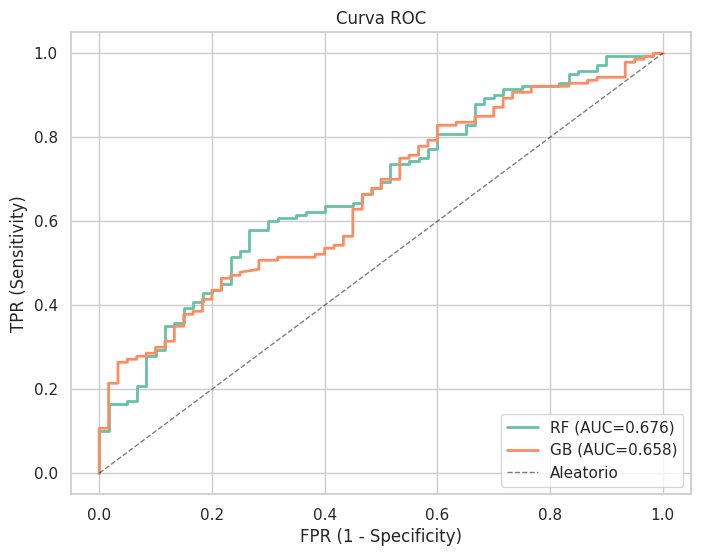

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for probs, label in [(rf_probs, f'RF (AUC={rf_auc:.3f})'), (gb_probs, f'GB (AUC={gb_auc:.3f})')]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, label=label, lw=2)
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Aleatorio')
ax.set(xlabel='FPR (1 - Specificity)', ylabel='TPR (Sensitivity)', title='Curva ROC')
ax.legend(loc='lower right'); plt.show()


## Análisis de Error
Dos enfoques: (1) probar el modelo con perfiles sintéticos diseñados a mano,
y (2) examinar los falsos positivos y falsos negativos del test set.


In [ ]:
# Perfiles sintéticos para probar el modelo manualmente
synthetic = pd.DataFrame({
    'Age': [22, 55, 45, 30, 60],
    'Sex': ['male', 'female', 'male', 'male', 'female'],
    'Job': [1, 2, 3, 2, 2],
    'Housing': ['rent', 'own', 'own', 'rent', 'own'],
    'Saving accounts': ['little', 'quite rich', 'rich', 'little', 'moderate'],
    'Checking account': ['little', 'moderate', 'rich', 'little', 'moderate'],
    'Credit amount': [8000, 1500, 3000, 10000, 1200],
    'Duration': [48, 12, 24, 60, 6],
    'Purpose': ['car', 'radio/TV', 'furniture/equipment', 'business', 'education'],
})

desc = [
    'joven, rent, crédito alto 48m',
    'adulto, own, ahorros altos, crédito bajo',
    'profesional, own, crédito medio',
    'emprendedor, rent, crédito muy alto 60m',
    'mayor, own, ahorros moderados',
]

# Obtener probabilidades y etiquetas
probs = best_model.predict_proba(synthetic)[:, 1]
preds = ['Good' if p >= 0.5 else 'Bad' for p in probs]

for i in range(len(synthetic)):
    print(f'{i+1}. {desc[i]}')
    print(f'   P(Good)={probs[i]:.2%}  →  {preds[i]}\n')


1. joven, rent, crédito alto 48m
   P(Good)=41.26%  →  Bad

2. adulto, own, ahorros altos, crédito bajo
   P(Good)=80.51%  →  Good

3. profesional, own, crédito medio
   P(Good)=82.09%  →  Good

4. emprendedor, rent, crédito muy alto 60m
   P(Good)=39.01%  →  Bad

5. mayor, own, ahorros moderados
   P(Good)=71.40%  →  Good



### Falsos positivos y falsos negativos
Identificamos los casos donde el modelo se equivoca y analizamos su perfil.
FP = prestar a quien no debía (costo directo). FN = rechazar a quien sí pagaba (costo de oportunidad).


In [ ]:
# Armar DataFrame con predicciones y probabilidades
results = X_test.copy()
results['real'] = y_test.values
results['pred'] = y_pred
results['prob'] = best_model.predict_proba(X_test)[:, 1]

# Filtrar errores
fp = results[(results['real'] == 0) & (results['pred'] == 1)]
fn = results[(results['real'] == 1) & (results['pred'] == 0)]

print(f'FP (aprobar a quien no debía): {len(fp)} — {len(fp)/len(y_test):.1%} del test')
print(f'FN (rechazar a quien sí pagaba): {len(fn)} — {len(fn)/len(y_test):.1%} del test')

# Mostrar hasta 3 ejemplos de cada tipo
if len(fp) > 0:
    print('\nEjemplos FP:')
    for idx in fp.index[:3]:
        r = results.loc[idx]
        print(f'  edad={X_test.loc[idx,"Age"]}, monto={X_test.loc[idx,"Credit amount"]}, '
              f'propósito={X_test.loc[idx,"Purpose"]}, prob={r["prob"]:.2%}')
if len(fn) > 0:
    print('\nEjemplos FN:')
    for idx in fn.index[:3]:
        r = results.loc[idx]
        print(f'  edad={X_test.loc[idx,"Age"]}, monto={X_test.loc[idx,"Credit amount"]}, '
              f'propósito={X_test.loc[idx,"Purpose"]}, prob={r["prob"]:.2%}')


FP (aprobar a quien no debía): 51 — 25.5% del test
FN (rechazar a quien sí pagaba): 7 — 3.5% del test

Ejemplos FP:
  edad=37, monto=12389, propósito=car, prob=53.76%
  edad=65, monto=2600, propósito=radio/TV, prob=81.29%
  edad=26, monto=3114, propósito=furniture/equipment, prob=63.01%

Ejemplos FN:
  edad=48, monto=12204, propósito=business, prob=48.47%
  edad=31, monto=6110, propósito=education, prob=48.64%
  edad=32, monto=11760, propósito=education, prob=35.55%


## Conclusiones y Limitaciones

### Resultados
- El baseline alcanza un AUC en test de 0.68 (Random Forest), lo que indica capacidad discriminativa
  no trivial, pero lejos de ser un clasificador confiable para producción.
- Ambos modelos (RF y GB) rinden de forma similar, con diferencias marginales que dependen
  de la semilla y la partición. Ninguno domina al otro de forma consistente.

### Limitaciones del baseline
- **Tamaño de muestra**: 1,000 instancias es poco para que estos modelos generalicen bien.
  La varianza entre folds de CV es alta (se puede observar en la diferencia AUC CV vs AUC Test).
- **Desbalance**: con ~70% good, un clasificador que siempre prediga good obtendría 70% de accuracy.
  Por eso usamos AUC, pero el modelo igual tiende a favorecer la clase mayoritaria.
- **Features**: 9 predictores sin engineered features ni datos externos.
  Variables como "Saving accounts" tienen mucho NA, lo que reduce su poder predictivo.
- **Costo asimétrico**: FP y FN no tienen el mismo costo para el negocio.
  El modelo no incorpora esta asimetría — un área de mejora directa.

### Próximo paso
Comparar estos resultados contra **TabPFN** usando el mismo test set exportado.
La hipótesis es que un foundation model entrenado en millones de datasets sintéticos
pueda superar este baseline con menos esfuerzo de tuning, especialmente en la franja
de small data (<10K muestras).
